# Estacionalidad en series temporales

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics import tsaplots

## 1. Lectura de datos

Leer, mediante pandas, los datos contenidos en "daily_min-temperatures.csv".

In [2]:
df = pd.read_csv("daily-min-temperatures.csv", header = 0)
df.head()

,Date,Temp
0,1981-01-01,20.7
1,1981-01-02,17.9
2,1981-01-03,18.8
3,1981-01-04,14.6
4,1981-01-05,15.8


## 2. Formato de columnas

Compueba el formato de las columnas y cámbialo si es necesario.

In [3]:
df.dtypes

Date     object
Temp    float64
dtype: object

Formateamos la columna de fechas y la definimos como índice del dataframe.

In [4]:
def parser(x):
	return  pd.to_datetime(x, format='%Y-%m-%d')
df = pd.read_csv("daily-min-temperatures.csv", header = 0, parse_dates=[0], index_col=0, date_parser=parser)
df.head()

C:\Users\icalvo\AppData\Local\Temp\ipykernel_21888\1467103354.py:3: FutureWarning: The argument 'date_parser' is deprecated and will be removed in a future version. Please use 'date_format' instead, or read your data in as 'object' dtype and then call 'to_datetime'.
  df = pd.read_csv("daily-min-temperatures.csv", header = 0, parse_dates=[0], index_col=0, date_parser=parser)


,Temp
Date,
1981-01-01,20.7
1981-01-02,17.9
1981-01-03,18.8
1981-01-04,14.6
1981-01-05,15.8


Formateamos la columna de fechas y la definimos como índice del dataframe.

## 3. Visualización de la serie


<Axes: title={'center': 'Daily Minimum Temperatures'}, xlabel='Date'>

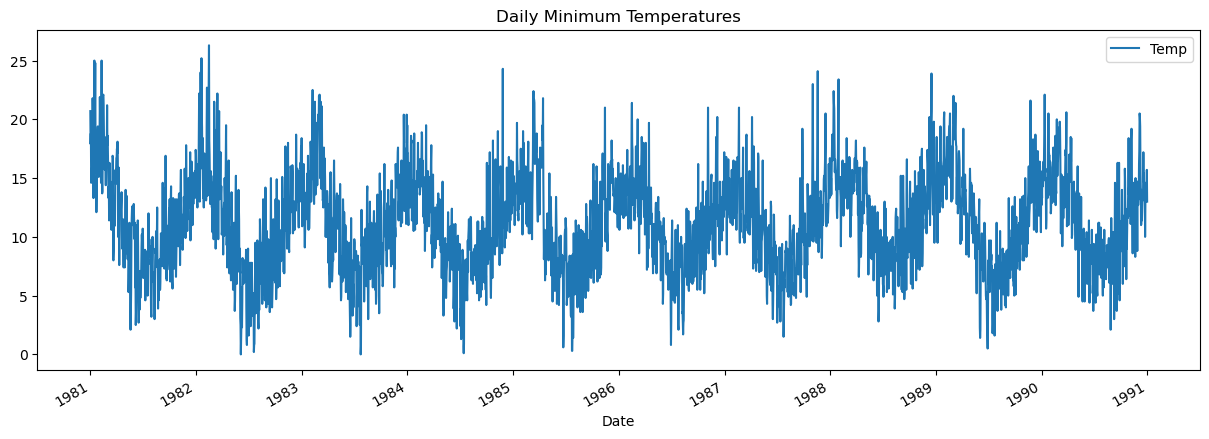

In [5]:
df.plot(figsize =(15,5), title = "Daily Minimum Temperatures")

## 4. Obtención y eliminación de la estacionalidad

### 4.1 Comprobación mediante función de autocorrelación


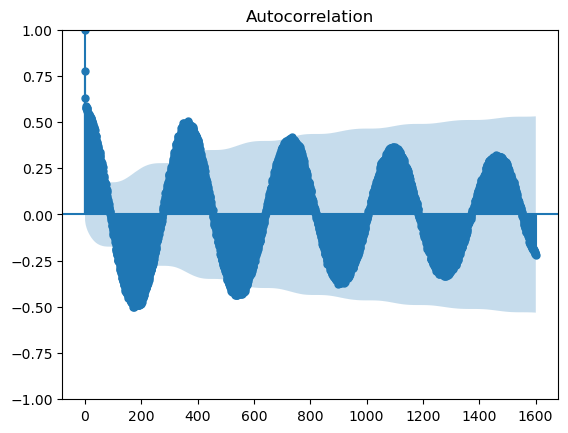

In [6]:
tsaplots.plot_acf(df, lags=1600)
plt.show()

### 4.2 Mediante la media móvil


<function matplotlib.pyplot.show(close=None, block=None)>

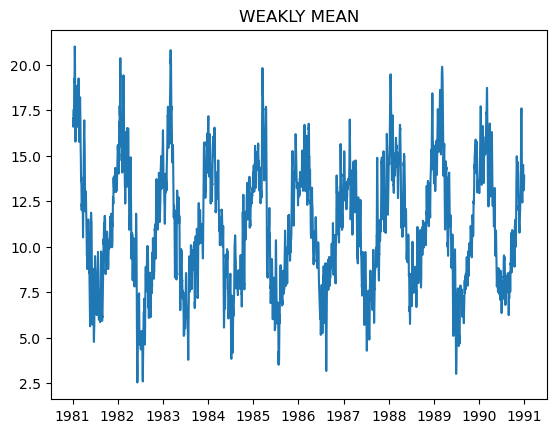

In [7]:
seasonality = df.rolling(7).mean()
plt.plot(seasonality)
plt.title("WEAKLY MEAN")
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

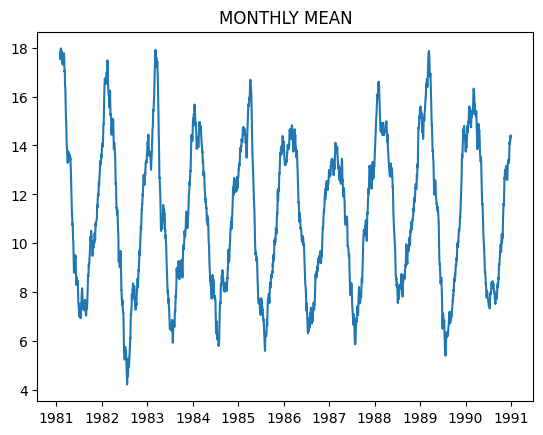

In [39]:
df["moving_avg"] = df.rolling(30).mean()
plt.plot(df["moving_avg"])
plt.title("MONTHLY MEAN")
plt.show

<function matplotlib.pyplot.show(close=None, block=None)>

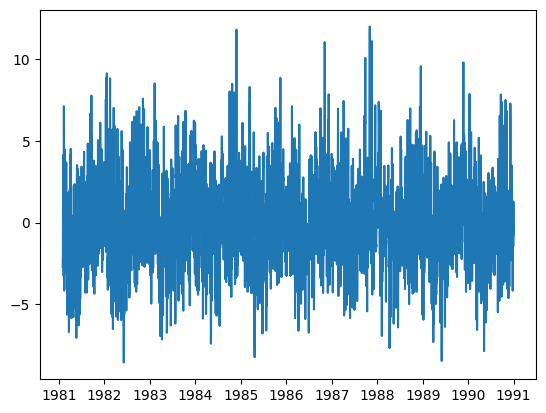

In [42]:
plt.plot(df["Temp"] - df["moving_avg"])
plt.show

¿Qué ocurre si cogemos la media anual?

<function matplotlib.pyplot.show(close=None, block=None)>

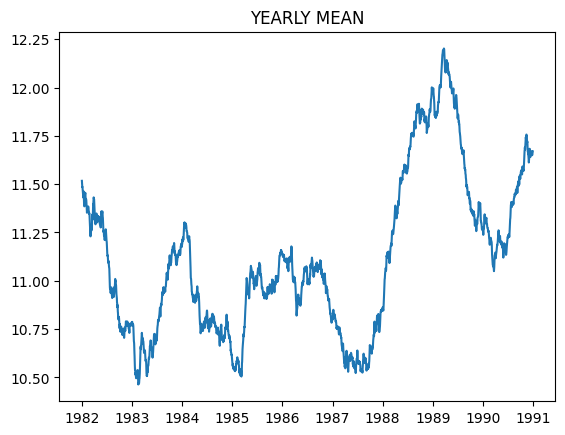

In [44]:
seasonality = df["Temp"].rolling(365).mean()
plt.plot(seasonality)
plt.title("YEARLY MEAN")
plt.show

Aunque parezca que oscila si nos fijamos en la amplid de oscilación (entre 10.5 y 12) es muy inferior a la amplitud de oscilación de la serie original (entre 0 y 25). Lo que estamos obteniendo es la media de la serie. 

### 4.3 Seasonal Decompose

<Axes: xlabel='Date'>

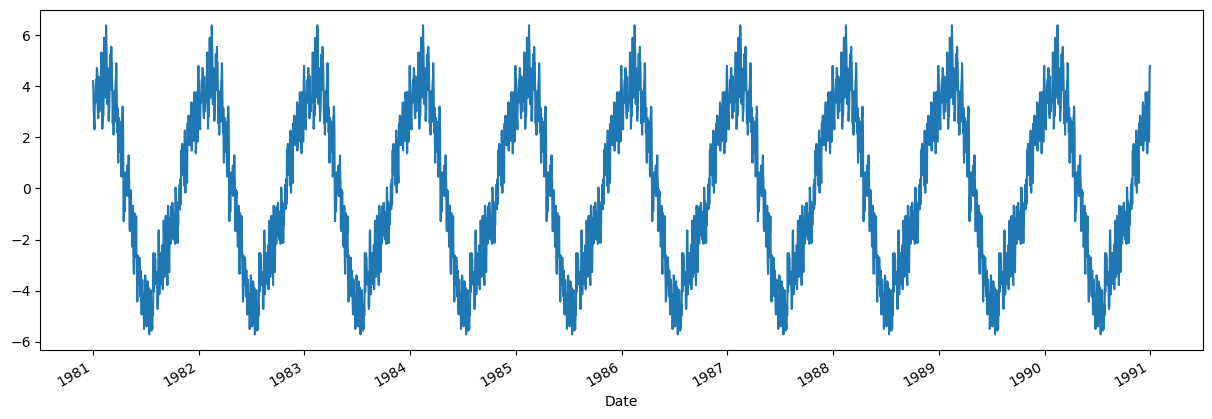

In [8]:
result = seasonal_decompose(df, model='additive',period=365)
result.seasonal.plot(figsize=(15,5))


In [26]:
serie_sin_estac = df["Temp"] - result.seasonal

<Axes: xlabel='Date'>

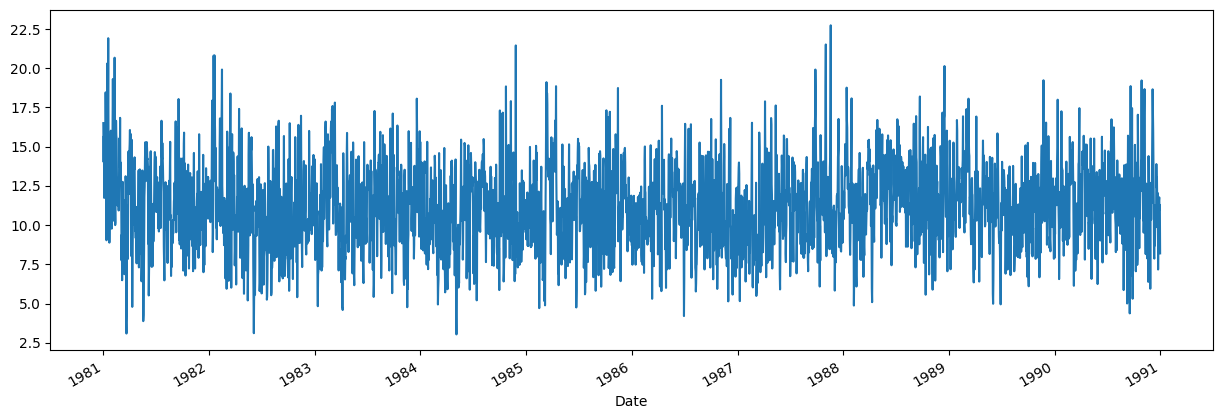

In [27]:
serie_sin_estac.plot(figsize=(15,5))

### 4.4 Diff

<Axes: xlabel='Date'>

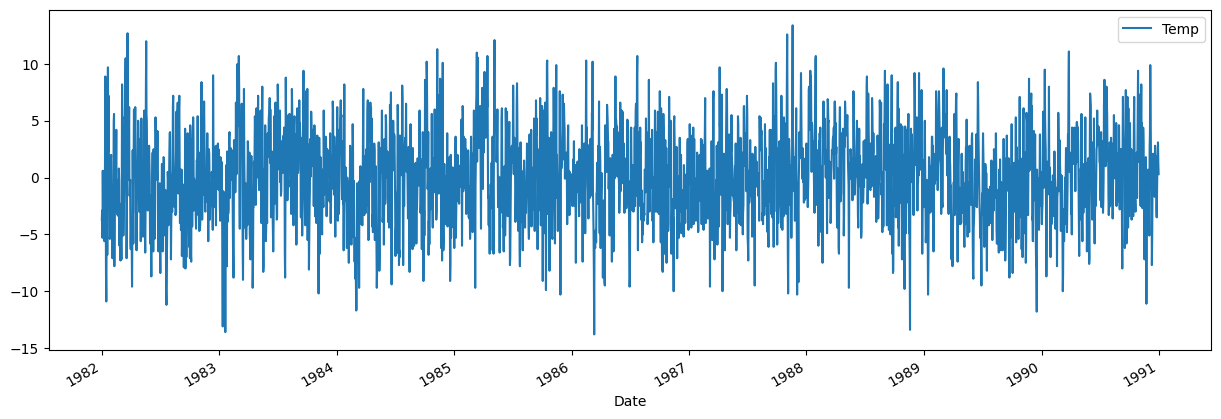

In [29]:
df.diff(periods=365).plot(figsize=(15,5))

### 4.5 Transformada de Fourier

C:\Users\icalvo\AppData\Local\Temp\ipykernel_21888\561438037.py:4: RuntimeWarning: divide by zero encountered in divide
  periods = 1 / frequencies


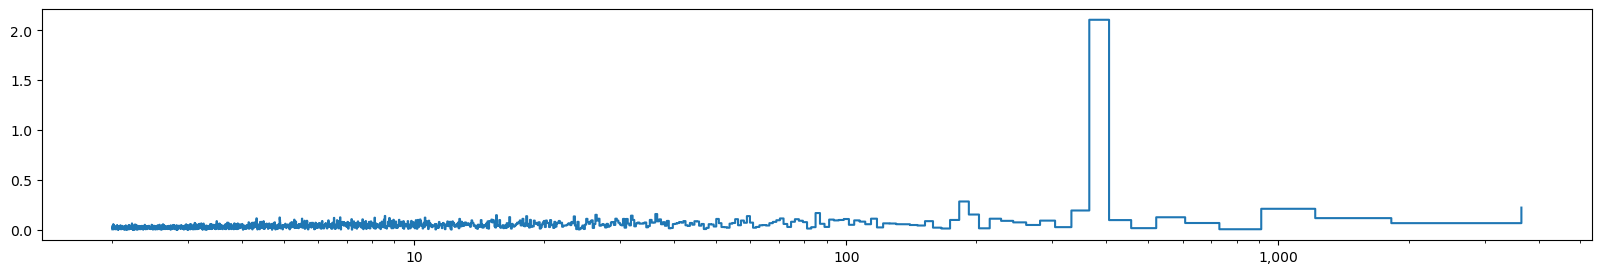

In [9]:
X = np.fft.fft(df['Temp'])
N = len(X)
frequencies = np.fft.fftfreq(N, 1)
periods = 1 / frequencies
fft_magnitude = np.abs(X) / N

mask = frequencies >= 0

# Plot de la transformada de Fourier
fig, ax = plt.subplots(figsize=(20, 3))
ax.step(periods[mask], fft_magnitude[mask]) #Frecuencias positivas
ax.set_xscale('log')
ax.xaxis.set_major_formatter('{x:,.0f}')


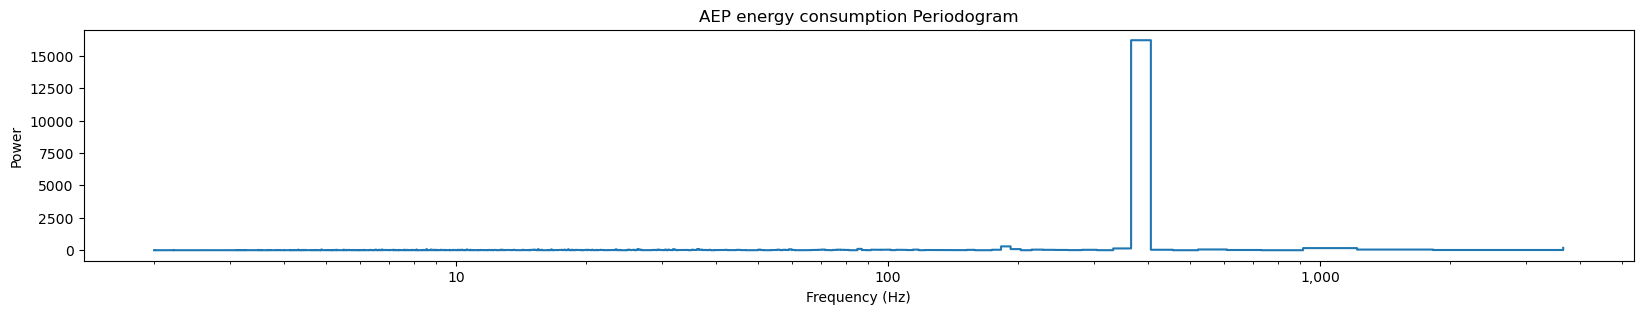

In [10]:
power_spectrum = np.abs(X)**2 / N # Intensidad de cada frecuencia = abs(TF^2) /número de frecs

fig, ax = plt.subplots(figsize=(20, 3))
ax.step(periods[mask], power_spectrum[mask])
ax.set_title('AEP energy consumption Periodogram')
ax.set_xscale('log')
ax.xaxis.set_major_formatter('{x:,.0f}')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power')
plt.show()

In [21]:
np.abs(periods[np.where(power_spectrum > 5000)])

array([ inf, 365., 365.])

365Hz que, con una frecuencia muestral diaria, corresponde a un periodo de un año.